## Question 1

- Programmatically download and load into your favorite analytical tool the trip data
for September 2024.
- Report how many rows and columns of data you have loaded. 

In [1]:
import pandas as pd

url = "https://d37ci6vzurychx.cloudfront.net/trip-data/green_tripdata_2024-09.parquet"
trips = pd.read_parquet(url)

trips.shape

(54440, 20)

The dataset has 54440 rows and 20 columns of data.

## Question 2

- Plot a histogram of the number of the trip distance ("Trip Distance").
- Report any structure you find and any hypotheses you have about that structure

In [2]:
trips["trip_distance"].describe()

count     54440.000000
mean         18.412486
std        1169.915825
min           0.000000
25%           1.180000
50%           1.980000
75%           3.590000
max      207968.060000
Name: trip_distance, dtype: float64

<Axes: title={'center': 'Trip distance (all trips)'}, ylabel='Frequency'>

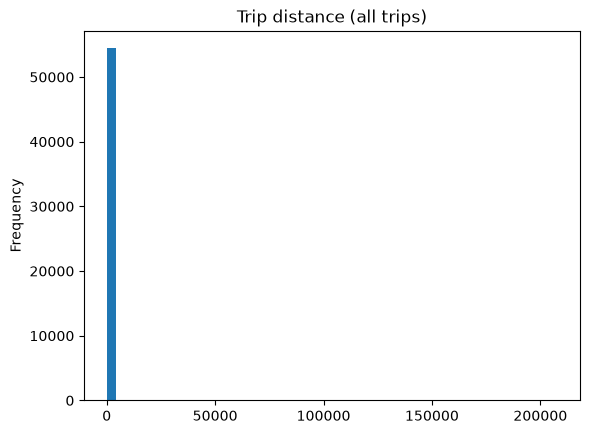

In [3]:
trips["trip_distance"].plot.hist(bins=50, title="Trip distance (all trips)")

<Axes: title={'center': 'Trip distance (under 20 miles)'}, ylabel='Frequency'>

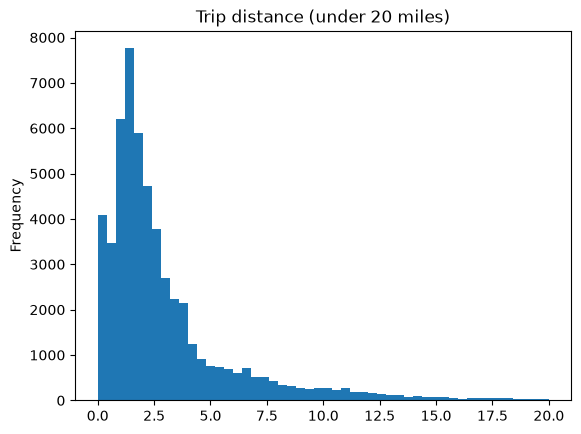

In [4]:
trips[trips["trip_distance"] < 20]["trip_distance"].plot.hist(bins=50, title="Trip distance (under 20 miles)")

In [5]:
(trips["trip_distance"] == 0).sum()

np.int64(2780)

- The median trip distance is 1.98 miles and the 75th percentile is 3.59. This means that most trips are quite short.
- The max trip distance is 207,968 miles, while the mean is 18.4. So a few extreme values likely skew the mean far above the median, which is why the first histogram is a poor depiction of the data. This was likely due to a driver never officially ending any trips.
- 2780 trips have a zero distance, which is about 5% of the data. There are a few possible explanations for this. These could be cancelled trips, passengers who immediately exited the vehicle, or trips with the same pickup and dropoff location.
- The distribution becomes heavily right skewred once the outliers have been removed. The peak is around 1.5  miles. Most trips seem to be shorter, likely due to green taxis being unable to pickup passengers in most of Manhattan. The first bin seems to be inflated by the previously mentioned zero distance trips. There are also a few highspots towards the tail, two notable ones being around 6-7 and 10-12 miles.

## Question 3

- Report mean and median trip distance grouped by hour of day.
- We'd like to get a rough sense of identifying trips that originate or terminate at one
of the NYC area airports. Can you provide a count of how many transactions fit this
criteria, the average fair, and any other interesting characteristics of these trips.

(I decided to assign trips to the hour in which the trip began. For example, a trip that starts at 4:45PM and ends at 5:01PM will count towards the 4PM hour.)

In [6]:
trips["pickup_hour"] = trips["lpep_pickup_datetime"].map(lambda t: t.hour)

In [ ]:
trips[trips["trip_distance"] < 100].groupby("pickup_hour").trip_distance.agg(["mean", "median"])

# Trips over 100 miles were removed from this table as green taxis only operate within NYC, meaning trips over 100 miles are assumed to be data errors.

,mean,median
pickup_hour,,
0,4.454244,2.565
1,3.385406,2.120
2,3.326494,2.170
3,3.761129,2.860
4,3.931751,2.520
5,4.472007,2.500
6,3.032248,1.680
7,2.709366,1.700
8,2.614307,1.700


- Late night and early morning tend to have the longest trips (~10PM to ~5AM). Means range from 3.3 to 4.6 miles and medians from range 2.1 to 2.9. The peak is at hours 22 and 23 (Mean of 4.59 and 4.63) and at hours 0 and 5.
- The daytime (~6AM to ~7PM) is flat and short. Means range from 2.6 to 3.0 miles and medians range 1.7 to 2.0 miles. The shortest trips are during morning commute hours, from around 6 to 8 with medians of 1.68 to 1.70.
- The mean is above the median for every hour, which is a matched by the right skew present in the Q2 histogram.

In [8]:
airport_ids = [1, 132, 138]
airport_trips = trips[trips.PULocationID.isin(airport_ids) | trips.DOLocationID.isin(airport_ids)]
airport_trips.shape

(2526, 21)

In [9]:
airport_trips[["fare_amount", "total_amount", "trip_distance", "tip_amount", "passenger_count"]].mean()

fare_amount        33.776995
total_amount       47.434181
trip_distance      33.509549
tip_amount          5.956920
passenger_count     1.412065
dtype: float64

In [10]:
trips[["fare_amount", "total_amount", "trip_distance", "tip_amount", "passenger_count"]].mean()

fare_amount        20.400262
total_amount       26.679474
trip_distance      18.412486
tip_amount          2.861957
passenger_count     1.318075
dtype: float64

In [11]:
airport_trips.trip_distance.median()

np.float64(4.6)

In [12]:
trips.PULocationID.isin(airport_ids).sum(), trips.DOLocationID.isin(airport_ids).sum()

(np.int64(85), np.int64(2493))

- There are 2526 trips that start or end at one of the three NYC airports. This is about 4.6% of all trips.
- The average fare is $33.78 for airport trips. The average fare for ALL trips is $20.40.
- Airport trips have higher tips on average, aswell as slightly more passengers. $5.96 vs. $2.86 for tips, and 1.41 vs. 1.32 for passenger count.
- Almost all airport trips are drop offs. 2493 trips end at the aiurport and only 85 start at one.
- The median airport trip is 4.6 miles. The mean trip distance for airport trips of 33.5 is skewed by data errors, meaning the median is a more accurate measure.

## Question 4
- Build a derived variable for tip as a percentage of the total fare.
- Build a predictive model for tip as a percentage of the total fare. Use as much of the data as you like (or all of it). We will validate a sample.

In [13]:
trips.payment_type.value_counts()

payment_type
1.0    38389
2.0    13843
3.0      390
4.0      110
5.0        4
Name: count, dtype: int64

In [14]:
card = trips[(trips.payment_type == 1) & (trips.total_amount > 0)]
card["tip_pct"] = card.tip_amount / card.total_amount * 100
card.tip_pct.describe()

count    38385.000000
mean        13.803896
std          7.416018
min          0.000000
25%          9.840098
50%         16.666667
75%         16.666667
max        100.000000
Name: tip_pct, dtype: float64

In [15]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error

features = ["fare_amount", "trip_distance", "pickup_hour", "passenger_count",
            "PULocationID", "DOLocationID", "tolls_amount",
            "VendorID", "trip_type", "RatecodeID", "extra", "congestion_surcharge"]

model_data = card[features + ["tip_pct"]].dropna(axis=0)
X = model_data[features]
y = model_data.tip_pct

train_X, val_X, train_y, val_y = train_test_split(X, y, random_state=0)

model = RandomForestRegressor(random_state=1)
model.fit(train_X, train_y)

print("Model MAE:", mean_absolute_error(val_y, model.predict(val_X)))
print("Baseline MAE:", mean_absolute_error(val_y, [train_y.median()] * len(val_y)))

Model MAE: 4.85135828714687
Baseline MAE: 4.803629724355177


- Tip percentage = tip_amount / total_amount * 100. Cash tips are not recorded.
- The random forest's MAE is very close to the baseline of guessing the median tip. So trip details are not effective at predicting tipping.

## Question 5

- Option A: Distributions
    - Build a derived variable representing the average speed over the
    course of a trip.
    - Can you perform a test to determine if the average trip speeds are
    materially the same in all weeks of September? If you decide they
    are not the same, can you form a hypothesis regarding why they
    differ?
    - Can you build up a hypothesis of average trip speed as a function of
    time of day?

In [16]:
trips["duration_hours"] = (trips.lpep_dropoff_datetime - trips.lpep_pickup_datetime).map(lambda d: d.total_seconds() / 3600)
trips.duration_hours.describe()

count    54440.000000
mean         0.345278
std          1.357166
min          0.000000
25%          0.133264
50%          0.210556
75%          0.328611
max         23.988333
Name: duration_hours, dtype: float64

In [17]:
speed = trips[(trips.duration_hours > 0) & (trips.trip_distance > 0)]
speed["speed_mph"] = speed.trip_distance / speed.duration_hours
speed.speed_mph.describe()

count     51650.000000
mean         79.731362
std        4211.305741
min           0.002996
25%           8.040676
50%          10.247358
75%          13.701377
max      425659.800000
Name: speed_mph, dtype: float64

In [18]:
(speed.speed_mph > 50).sum(), (speed.speed_mph > 80).sum(), (speed.speed_mph > 100).sum()

(np.int64(264), np.int64(197), np.int64(179))

In [19]:
speed = speed[speed.speed_mph < 80]
speed.speed_mph.describe()

count    51452.000000
mean        11.780919
std          6.227175
min          0.002996
25%          8.027755
50%         10.230215
75%         13.631684
max         78.545455
Name: speed_mph, dtype: float64

- Trips with a spead of 80mph or more were removed as data errors. The majoirty of these trips were over 100mph. The cleaned data set has 51452 trips with a mean of 11.8mph and median of 10.2mph.

In [20]:
speed = speed[speed.lpep_pickup_datetime.map(lambda t: t.year == 2024 and t.month == 9)]
speed["week"] = speed.lpep_pickup_datetime.map(lambda t: (t.day - 1) // 7 + 1)
print(len(speed))
speed.groupby("week").speed_mph.agg(["count", "mean", "median"])

51428


,count,mean,median
week,,,
1,11977,12.760148,10.781841
2,11598,11.406263,10.022376
3,12275,11.428462,9.996117
4,12429,11.500596,10.083942
5,3149,11.853988,10.588235


In [21]:
weekly = speed.groupby("week").speed_mph.agg(["count", "mean", "std"])
weekly["margin"] = 1.96 * weekly["std"] / weekly["count"] ** 0.5
weekly["low"] = weekly["mean"] - weekly["margin"]
weekly["high"] = weekly["mean"] + weekly["margin"]
weekly

,count,mean,std,margin,low,high
week,,,,,,
1,11977,12.760148,7.133657,0.127760,12.632388,12.887907
2,11598,11.406263,5.727399,0.104237,11.302026,11.510500
3,12275,11.428462,5.934730,0.104990,11.323473,11.533452
4,12429,11.500596,5.955096,0.104695,11.395901,11.605291
5,3149,11.853988,6.001979,0.209635,11.644353,12.063624


<Axes: title={'center': 'Average speed by week (mph)'}, xlabel='week'>

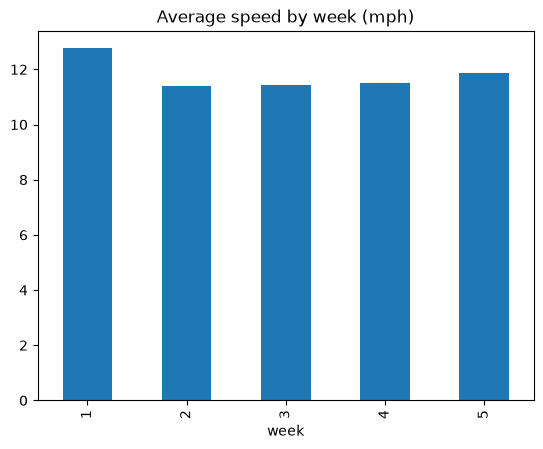

In [22]:
weekly["mean"].plot.bar(title="Average speed by week (mph)")

- I decided to compare the 95% confidence intervals of the average speed for each week. Week 1 has a average speed of 12.76mph, which does not overlap with any other week and is about 1.3mph faster than weeks 2-4. Weeks 2-4 do overlap with eachother (~11.4-11.5mph). Week 5 is slightly higher at 11.85mph, but only has 2 days covered.
- A reason why this is the case may be that week 1 includes a holiday, Labor Day, when there is less traffic. Week 5 contains a Sunday and Monday which means a larger share of its trips are on Sunday, which could make the average speed faster.

In [23]:
speed.groupby("pickup_hour").speed_mph.agg(["count", "mean", "median"])

,count,mean,median
pickup_hour,,,
0,1148,16.979177,13.831791
1,612,15.058426,12.902830
2,414,14.823947,13.333846
3,328,16.484640,14.700988
4,271,17.934542,15.200000
5,262,18.685480,16.719919
6,862,14.579964,12.633236
7,1837,11.704405,9.870257
8,2302,10.392459,8.961021


- The average speed varies with time of day. Average speed is highest overnight and in the early morning, hours 0-5 experience speeds of around 15-19mph, and peak at 18.7mph at 5am. Speeds are lowest in the afternoon, at about 9.9-10.5mph from hours 14-17. There is a large drop in speed btween 6 and 7am, likely due to morning commuters. As the day progresses, speed recovers steadily throughout the evening.
- Average speed is likely inversely related to traffic. Roads are more empty overnight, and congested during the day. The overnight hours have significantly fewer trips, meaning the averages are also less reliable.